In [19]:
import sys
import os
import json
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [20]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [21]:
ll = 'll00'
data_variants = [
	'gcamp',
	'gfp',
]
model_variant = 'ns'
organism = 'worm-2025-fieseler'

In [22]:
if 'gcamp' in data_variants:
	# file_ids_gcamp = list(range(0, 33+1))
	file_ids_gcamp = [19]

	path_gcamp = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
	filenames_gcamp = [read_utils.get_filename(read_utils.get_file_handle(path_gcamp, file_id)) for file_id in file_ids_gcamp]

if 'gfp' in data_variants:
	file_ids_gfp = list(range(0, 7+1))
	# file_ids_gfp = [2]

	path_gfp = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	filenames_gfp = [read_utils.get_filename(read_utils.get_file_handle(path_gfp, file_id)) for file_id in file_ids_gfp]

In [23]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

if 'gcamp' in data_variants:
	bom_folder_gcamp = (f'{'gcamp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gcamp = (f'{'gcamp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

if 'gfp' in data_variants:
	bom_folder_gfp = (f'{'gfp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gfp = (f'{'gfp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [24]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [25]:
if 'gcamp' in data_variants:
	boms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gcamp), filename)[0] for filename in filenames_gcamp]
	hgms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gcamp), filename)[0] for filename in filenames_gcamp]

if 'gfp' in data_variants:
	boms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gfp), filename)[0] for filename in filenames_gfp]
	hgms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gfp), filename)[0] for filename in filenames_gfp]

In [26]:
if 'gcamp' in data_variants:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

if 'gfp' in data_variants:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

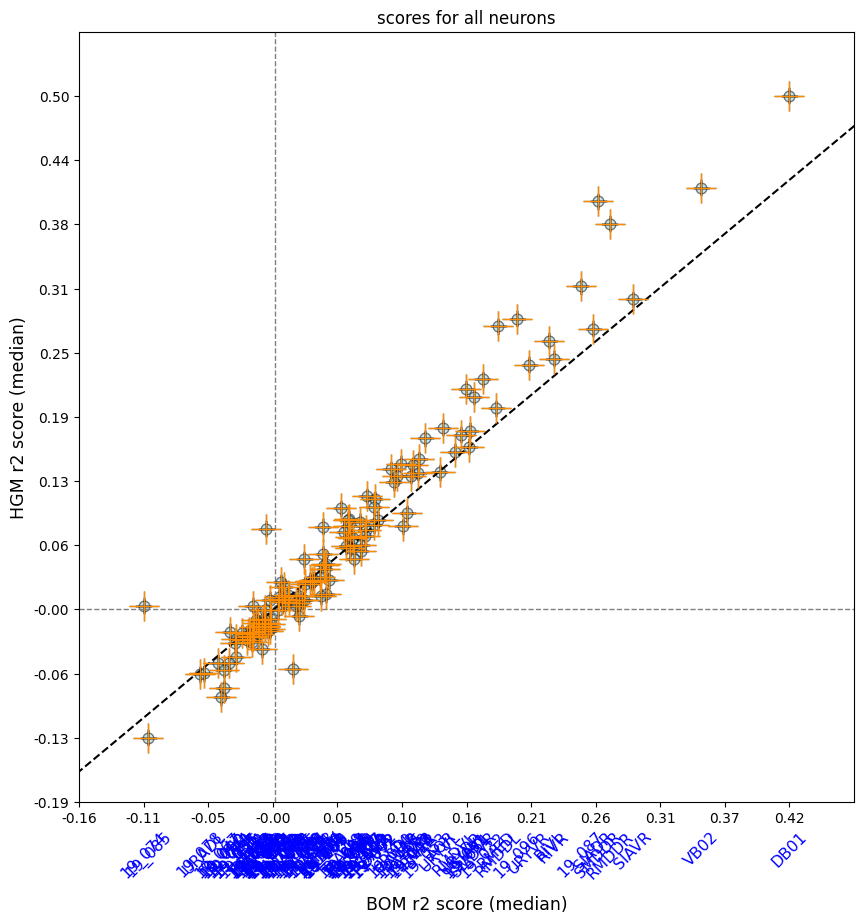

In [27]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, None,
		title='scores for all neurons', limits=None, force_medians=True
	)

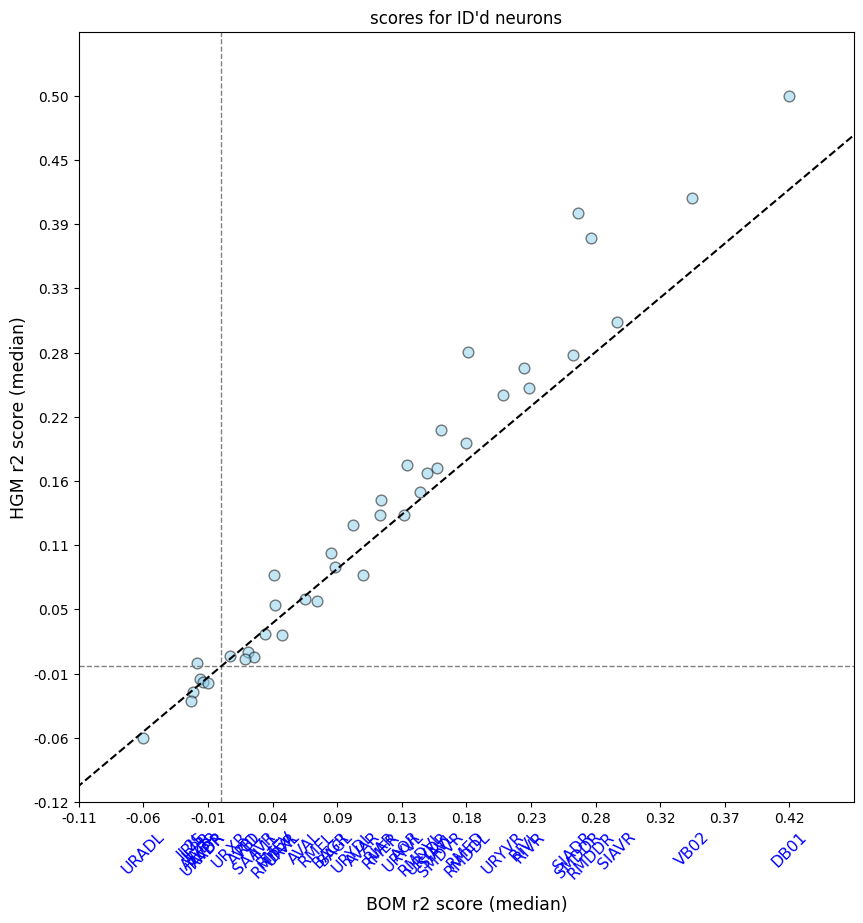

In [28]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=None
	)

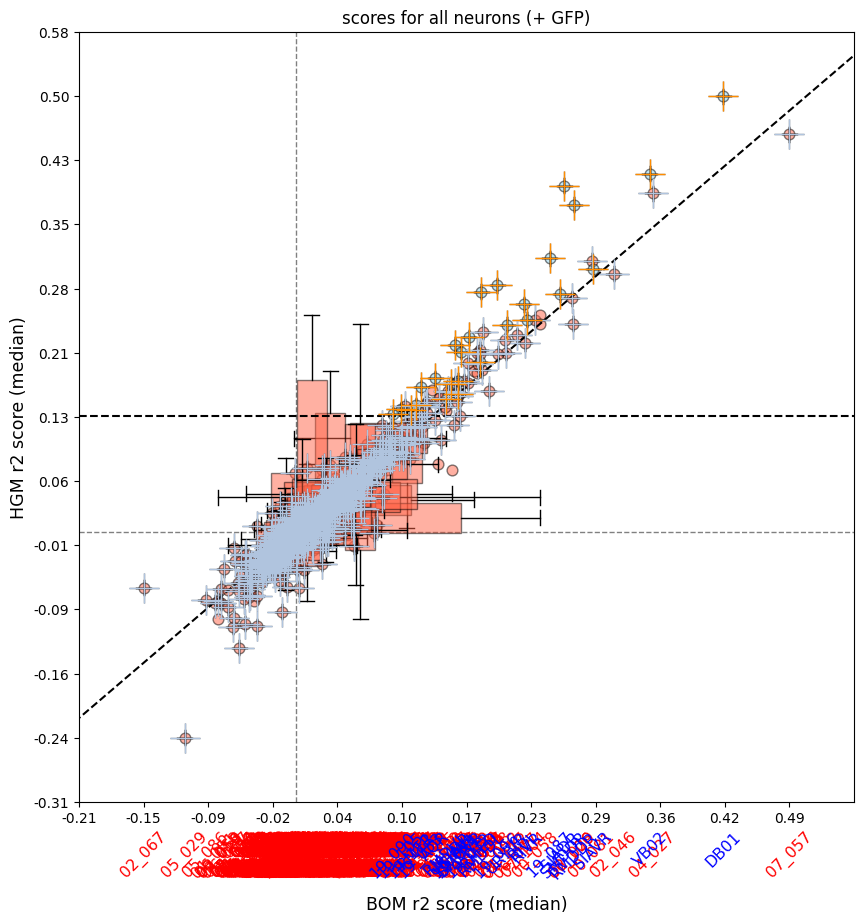

In [29]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, neuron_scores_gfp,
		title='scores for all neurons (+ GFP)', limits=None, force_medians=True
	)

In [30]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	significant_hgm_n_gcamp = list()
	for key in neuron_scores_gcamp.keys():
		scores_bom, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_bom = scores_bom.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)
		y = np.median(scores_hgm)
		if y > threshold_hgm_gfp:
			significant_hgm_n_gcamp.append(key)

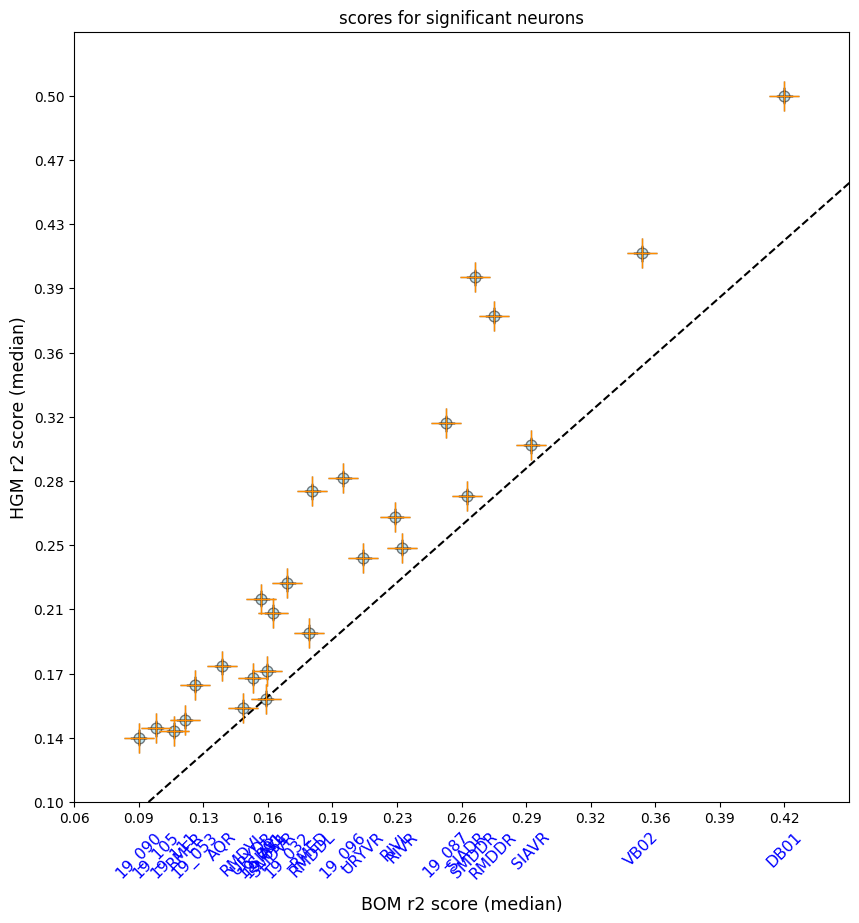

In [31]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp}, None,
		title='scores for significant neurons', limits=None, force_medians=True
	)

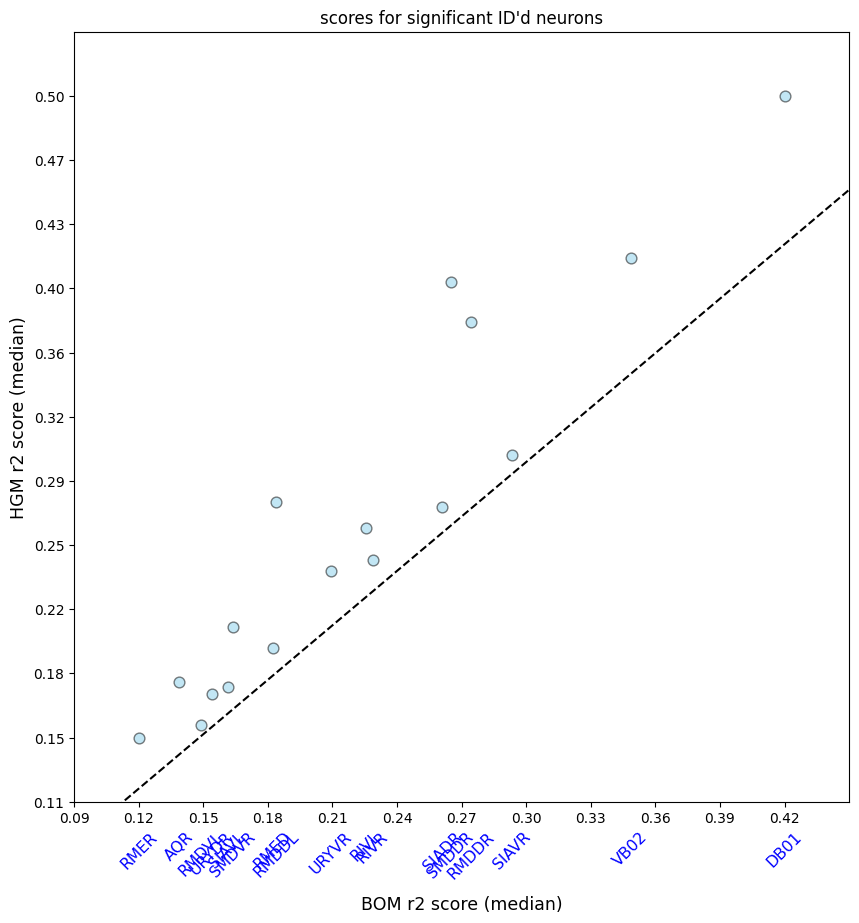

In [32]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='scores for significant ID\'d neurons', limits=None
	)

In [33]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	print('\n'.join([f'NEURON: {key},\tHGM: {np.median(val[1]):.4f}\tBOM: {np.median(val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: DB01,	HGM: 0.5026	BOM: 0.4203
NEURON: VB02,	HGM: 0.4127	BOM: 0.3483
NEURON: SMDDR,	HGM: 0.3992	BOM: 0.2641
NEURON: RMDDR,	HGM: 0.3773	BOM: 0.2737
NEURON: SIAVR,	HGM: 0.3032	BOM: 0.2926
NEURON: RMDDL,	HGM: 0.2770	BOM: 0.1824
NEURON: SIADR,	HGM: 0.2743	BOM: 0.2601
NEURON: RIVL,	HGM: 0.2625	BOM: 0.2243
NEURON: RIVR,	HGM: 0.2448	BOM: 0.2277
NEURON: URYVR,	HGM: 0.2392	BOM: 0.2080
NEURON: SMDVR,	HGM: 0.2078	BOM: 0.1624
NEURON: RMED,	HGM: 0.1964	BOM: 0.1809
NEURON: AQR,	HGM: 0.1774	BOM: 0.1370
NEURON: SIAVL,	HGM: 0.1744	BOM: 0.1596
NEURON: URYDR,	HGM: 0.1706	BOM: 0.1522
NEURON: RMDVL,	HGM: 0.1536	BOM: 0.1473
NEURON: RMER,	HGM: 0.1464	BOM: 0.1181


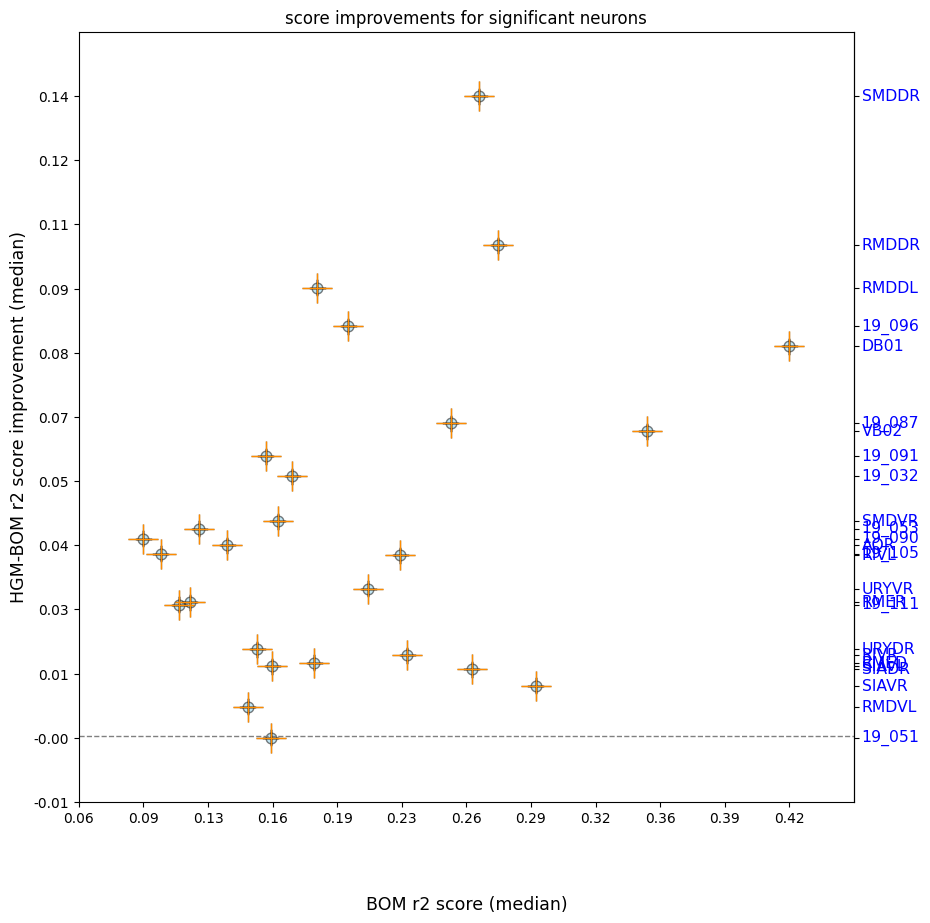

In [34]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp},
		title='score improvements for significant neurons', limits=None, force_medians=True
	)

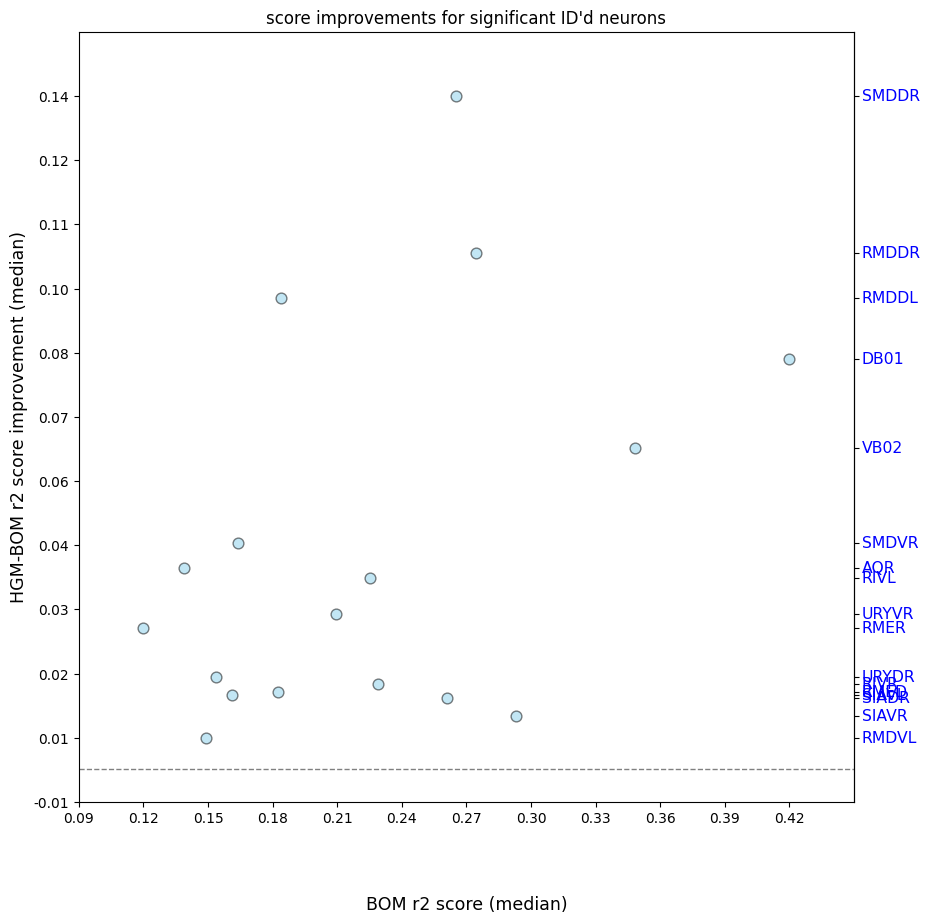

In [35]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='score improvements for significant ID\'d neurons', limits=None
	)

In [36]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	print('\n'.join([f'NEURON: {key},\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1] - x[1][0]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: SMDDR,	IMPR: 0.1351
NEURON: RMDDR,	IMPR: 0.1036
NEURON: RMDDL,	IMPR: 0.0946
NEURON: DB01,	IMPR: 0.0823
NEURON: VB02,	IMPR: 0.0644
NEURON: SMDVR,	IMPR: 0.0454
NEURON: AQR,	IMPR: 0.0404
NEURON: RIVL,	IMPR: 0.0383
NEURON: URYVR,	IMPR: 0.0312
NEURON: RMER,	IMPR: 0.0283
NEURON: URYDR,	IMPR: 0.0184
NEURON: RIVR,	IMPR: 0.0171
NEURON: RMED,	IMPR: 0.0155
NEURON: SIAVL,	IMPR: 0.0148
NEURON: SIADR,	IMPR: 0.0142
NEURON: SIAVR,	IMPR: 0.0106
NEURON: RMDVL,	IMPR: 0.0063
